# 🧠 Activité pratique n°4 – Architecture Transformer

**Objectif :** comprendre l'évolution des architectures séquentielles en les comparant sur une même tâche — la **prédiction d'une série temporelle** (`sin(x)`) — puis découvrir deux grandes familles de Transformers pré-entraînés : **GPT** (décodeur) et **BERT** (encodeur).

| Partie | Contenu |
|---|---|
| 1 | Préparer la série temporelle (fenêtre glissante, DataLoader) |
| 2 | RNN |
| 3 | LSTM |
| 4 | Transformer *from scratch* + comparaison RNN / LSTM / Transformer |
| 5 | GPT : décodeur + attention causale |
| 6 | BERT : encodeur + attention bidirectionnelle |
| ✔ | Conclusion comparative |



## 0. Installation et configuration

Nous importons les bibliothèques, **fixons les graines aléatoires** (reproductibilité) et choisissons le périphérique de calcul (GPU si disponible).

La bibliothèque `transformers` (Hugging Face) n'est nécessaire que pour les parties 5 et 6.

In [5]:
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# ---------------------------------------------------------------
# Reproductibilité : on fixe TOUTES les graines aléatoires
# ---------------------------------------------------------------
SEED = 42

def set_seed(seed: int = SEED):
    """Fixe les graines de Python, NumPy et PyTorch (CPU + GPU)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# Périphérique de calcul : GPU si disponible, sinon CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | périphérique : {device}")

# Style global des graphiques
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

PyTorch 2.15.0+cpu | périphérique : cpu


# 📈 PARTIE 1 – Préparer une série temporelle

### Principe de la fenêtre glissante

On génère `s = sin(x)` avec **200 points** pour `x ∈ [0, 20]`. On veut prédire la **valeur suivante** à partir des **10 valeurs précédentes** :

```
 s :  s0 s1 s2 s3 s4 s5 s6 s7 s8 s9 s10 s11 s12 ...
      └──────────── X1 ───────────┘  ↓
                                     y1 = s10
         └──────────── X2 ───────────┘  ↓
                                        y2 = s11
            └──────────── X3 ───────────┘  ↓
                                           y3 = s12      ... etc.
```

Avec 200 points et une fenêtre de 10, on obtient **200 − 10 = 190 échantillons**.

**Dimensions des tenseurs :**
```
X : (N, seq_len, n_features) = (190, 10, 1)   # n_features = 1 car série univariée
y : (N, 1)                                    # une valeur cible par séquence
```

Le découpage **train / test est chronologique** (80 % / 20 %, sans mélange) : on entraîne sur le « passé » et on teste sur le « futur », comme dans un vrai problème de prévision.

In [5]:
# ---------------------------------------------------------------
# 1) Génération de la série s = sin(x)
# ---------------------------------------------------------------
N_POINTS = 200        # nombre de points de la série
SEQ_LEN  = 10         # longueur de la fenêtre d'entrée

x_vals = np.linspace(0, 20, N_POINTS)       # 200 valeurs de x entre 0 et 20
s_vals = np.sin(x_vals).astype(np.float32)  # série temporelle s = sin(x)

# ---------------------------------------------------------------
# 2) Fenêtre glissante : X = [s_i ... s_{i+9}]  ->  y = s_{i+10}
# ---------------------------------------------------------------
def make_sequences(series: np.ndarray, seq_len: int):
    """Construit les couples (X, y) par fenêtre glissante."""
    X, y = [], []
    for i in range(len(series) - seq_len):
        X.append(series[i : i + seq_len])   # fenêtre de seq_len valeurs
        y.append(series[i + seq_len])       # valeur qui suit la fenêtre
    X = np.array(X, dtype=np.float32)       # (N, seq_len)
    y = np.array(y, dtype=np.float32)       # (N,)
    return X, y

X_all, y_all = make_sequences(s_vals, SEQ_LEN)
print("X_all :", X_all.shape, "| y_all :", y_all.shape)

# Vérification sur les premiers échantillons : y1 = s10, y2 = s11 ...
assert np.allclose(X_all[0], s_vals[0:10]) and np.isclose(y_all[0], s_vals[10])
assert np.allclose(X_all[1], s_vals[1:11]) and np.isclose(y_all[1], s_vals[11])
print("✔ Vérification de la fenêtre glissante OK")

# ---------------------------------------------------------------
# 3) Séparation train / test (chronologique, 80 % / 20 %)
# ---------------------------------------------------------------
n_train = int(0.8 * len(X_all))
X_train, y_train = X_all[:n_train], y_all[:n_train]
X_test,  y_test  = X_all[n_train:], y_all[n_train:]

# ---------------------------------------------------------------
# 4) Conversion en tenseurs PyTorch avec la forme (N, seq_len, 1) pour X et (N, 1) pour y
# ---------------------------------------------------------------
X_train_t = torch.tensor(X_train).unsqueeze(-1)   # (N_train, 10, 1)
y_train_t = torch.tensor(y_train).unsqueeze(-1)   # (N_train, 1)
X_test_t  = torch.tensor(X_test).unsqueeze(-1)    # (N_test, 10, 1)
y_test_t  = torch.tensor(y_test).unsqueeze(-1)    # (N_test, 1)

print(f"X_train : {tuple(X_train_t.shape)} | y_train : {tuple(y_train_t.shape)}")
print(f"X_test  : {tuple(X_test_t.shape)}  | y_test  : {tuple(y_test_t.shape)}")

# ---------------------------------------------------------------
# 5) Dataset + DataLoader (mini-batchs de 16, mélange seulement pour le train)
# ---------------------------------------------------------------
BATCH_SIZE = 16
g = torch.Generator().manual_seed(SEED)   # générateur dédié -> mélange reproductible
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                          batch_size=BATCH_SIZE, shuffle=True, generator=g)

xb, yb = next(iter(train_loader))
print(f"Un batch : X = {tuple(xb.shape)} (batch, seq_len, features) | y = {tuple(yb.shape)}")

# Abscisses correspondant aux cibles (utile pour les graphiques)
x_targets      = x_vals[SEQ_LEN:]          # x associé à chaque y
x_targets_test = x_targets[n_train:]       # partie test

X_all : (190, 10) | y_all : (190,)
✔ Vérification de la fenêtre glissante OK
X_train : (152, 10, 1) | y_train : (152, 1)
X_test  : (38, 10, 1)  | y_test  : (38, 1)
Un batch : X = (16, 10, 1) (batch, seq_len, features) | y = (16, 1)


### Visualisation de la série

On affiche le sinus complet, la zone d'entraînement / de test, ainsi qu'un exemple de fenêtre (10 points d'entrée) et sa cible.

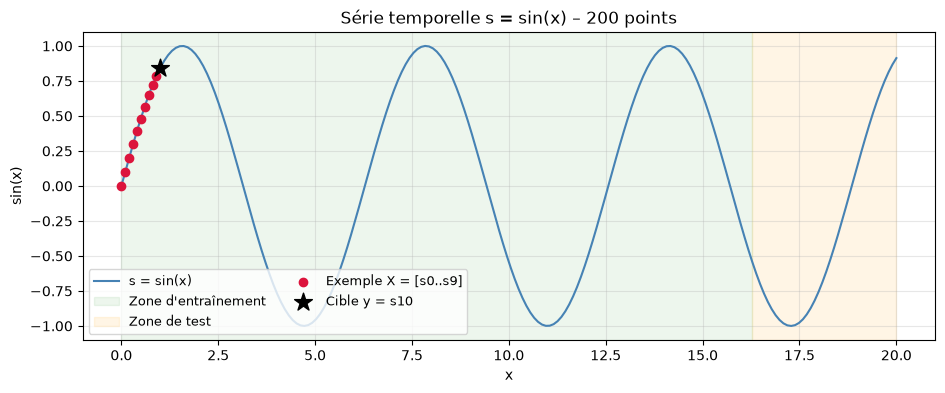

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(x_vals, s_vals, color="steelblue", label="s = sin(x)")

# Zones train / test (sur les cibles)
split_x = x_targets[n_train]
ax.axvspan(x_vals[0], split_x, color="green", alpha=0.07, label="Zone d'entraînement")
ax.axvspan(split_x, x_vals[-1], color="orange", alpha=0.10, label="Zone de test")

# Exemple de fenêtre glissante : X = [s0..s9] -> y = s10
ax.scatter(x_vals[:SEQ_LEN], s_vals[:SEQ_LEN], color="crimson", zorder=3, label="Exemple X = [s0..s9]")
ax.scatter(x_vals[SEQ_LEN], s_vals[SEQ_LEN], color="black", marker="*", s=180, zorder=4, label="Cible y = s10")

ax.set_title("Série temporelle s = sin(x) – 200 points")
ax.set_xlabel("x"); ax.set_ylabel("sin(x)")
ax.legend(loc="lower left", ncol=2, fontsize=9)
plt.show()

### Outils communs (entraînement, évaluation, graphiques)

Pour comparer équitablement les modèles, nous définissons des fonctions **réutilisables** :

- `count_parameters` : nombre de paramètres entraînables ;
- `train_model` : boucle d'entraînement (**MSE + Adam**), qui enregistre la loss d'entraînement et de test à chaque époque ;
- `evaluate_model` : prédictions + MSE sur le jeu de test ;
- `plot_loss`, `plot_predictions`, `plot_single_prediction` : visualisations.

**Boucle d'entraînement (rappel) :**
```
pour chaque époque :
    pour chaque mini-batch (X, y) :
        ŷ    = modèle(X)            # passe avant
        loss = MSE(ŷ, y)            # erreur quadratique moyenne
        loss.backward()             # rétropropagation (gradients)
        optimizer.step()            # mise à jour des poids (Adam)
```

In [9]:
# Dictionnaire global qui stocke les résultats de chaque modèle (pour la comparaison finale)
results = {}


def count_parameters(model: nn.Module) -> int:
    """Nombre de paramètres entraînables d'un modèle."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train_model(model, train_loader, X_test, y_test, epochs=100, lr=1e-2, verbose_every=20):
    """Entraîne `model` avec MSE + Adam. Retourne l'historique des pertes."""
    model.to(device)
    criterion = nn.MSELoss()                                  # fonction de perte
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)   # optimiseur
    history = {"train": [], "test": []}

    for epoch in range(1, epochs + 1):
        # ---------- Phase d'entraînement ----------
        model.train()
        running_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()              # remise à zéro des gradients
            y_hat = model(xb)                  # passe avant : (batch, 1)
            loss = criterion(y_hat, yb)        # MSE
            loss.backward()                    # rétropropagation
            optimizer.step()                   # mise à jour des poids
            running_loss += loss.item() * xb.size(0)
        history["train"].append(running_loss / len(train_loader.dataset))

        # ---------- Phase d'évaluation (sans gradient) ----------
        model.eval()
        with torch.no_grad():
            test_loss = criterion(model(X_test.to(device)), y_test.to(device)).item()
        history["test"].append(test_loss)

        if epoch == 1 or epoch % verbose_every == 0:
            print(f"Époque {epoch:4d}/{epochs} | loss train = {history['train'][-1]:.6f} | loss test = {test_loss:.6f}")
    return history


@torch.no_grad()
def evaluate_model(model, X, y):
    """Retourne (prédictions numpy 1D, MSE) sur (X, y)."""
    model.eval()
    preds = model(X.to(device)).cpu()                 # (N, 1)
    mse = F.mse_loss(preds, y).item()
    return preds.numpy().ravel(), mse


def plot_loss(history, title):
    """Courbe de loss (échelle log) train vs test."""
    plt.figure(figsize=(8, 3.6))
    plt.plot(history["train"], label="Loss train")
    plt.plot(history["test"], label="Loss test", linestyle="--")
    plt.yscale("log")
    plt.xlabel("Époque"); plt.ylabel("MSE (log)")
    plt.title(f"Courbe de loss – {title}")
    plt.legend(); plt.show()


def plot_predictions(y_true, y_pred, title):
    """Compare prédictions et vraies valeurs sur tout le jeu de test."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    axes[0].plot(x_targets_test, y_true, "o-", label="Vraie valeur", color="steelblue")
    axes[0].plot(x_targets_test, y_pred, "x--", label="Prédiction", color="crimson")
    axes[0].set_title(f"{title} – prédictions sur le jeu de test")
    axes[0].set_xlabel("x"); axes[0].legend()

    axes[1].scatter(y_true, y_pred, color="crimson", alpha=0.7)
    lims = [-1.1, 1.1]
    axes[1].plot(lims, lims, "k--", label="Prédiction parfaite")
    axes[1].set_xlim(lims); axes[1].set_ylim(lims)
    axes[1].set_title("Prédit vs réel"); axes[1].set_xlabel("Réel"); axes[1].set_ylabel("Prédit")
    axes[1].legend()
    plt.show()


@torch.no_grad()
def plot_single_prediction(model, idx, title):
    """Prédit la valeur suivante d'UNE séquence de X_test et la compare à la vraie valeur."""
    model.eval()
    seq = X_test_t[idx : idx + 1]                         # (1, 10, 1)
    y_hat = model(seq.to(device)).item()                  # valeur prédite
    y_true = y_test_t[idx].item()                         # vraie valeur

    g_idx = n_train + idx                                 # indice global dans la série
    x_in = x_vals[g_idx : g_idx + SEQ_LEN]                # abscisses des 10 entrées
    x_next = x_vals[g_idx + SEQ_LEN]                      # abscisse de la cible

    plt.figure(figsize=(8, 3.6))
    plt.plot(x_in, seq.squeeze().numpy(), "o-", color="steelblue", label="Séquence X_test (10 pas)")
    plt.scatter(x_next, y_true, color="green", s=120, zorder=3, label=f"Vraie valeur = {y_true:.4f}")
    plt.scatter(x_next, y_hat, color="crimson", marker="x", s=140, zorder=4, label=f"Prédiction = {y_hat:.4f}")
    plt.title(f"{title} – prédiction de la valeur suivante (échantillon test n°{idx})")
    plt.xlabel("x"); plt.legend(); plt.show()
    print(f"Vraie valeur : {y_true:.5f} | Prédiction : {y_hat:.5f} | Erreur absolue : {abs(y_true - y_hat):.5f}")

# 🔁 PARTIE 2 – RNN (Recurrent Neural Network)

### Architecture

Un RNN lit la séquence **pas à pas** et met à jour un **état caché** `h_t` qui résume le passé :

$$h_t = \tanh(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b)$$

```
 h0 = 0
   │
   ▼
 [RNN]──h1──[RNN]──h2──[RNN]── ... ──[RNN]──h10 = hn
   ▲          ▲          ▲               ▲
   x1         x2         x3              x10

 hn  (batch, 16)  ──►  Linear(16 → 1)  ──►  ŷ (batch, 1)
```

**Dimensions des tenseurs :**
```
Entrée x          : (batch, seq_len, 1)  = (B, 10, 1)
h0                : (num_layers, B, 16)  = (1, B, 16)    # initialisé à zéro
Sorties out       : (B, 10, 16)          # tous les états cachés h1..h10
Dernier état hn   : (1, B, 16) → hn[-1] : (B, 16)
Linear 16 → 1     : (B, 16) → (B, 1)     # ŷ
```

⚠️ **Limite :** le gradient doit traverser les 10 pas de temps (*vanishing gradient*) et le calcul est séquentiel (non parallélisable).

In [10]:
class RNNModel(nn.Module):
    """RNN (16 unités) -> dernier état caché -> Linear(16 -> 1)."""

    def __init__(self, input_size=1, hidden_size=16):
        super().__init__()
        self.hidden_size = hidden_size
        # batch_first=True : les tenseurs ont la forme (batch, seq_len, features)
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x : (B, seq_len, 1)
        h0 = torch.zeros(1, x.size(0), self.hidden_size, device=x.device)  # h0 = 0 : (1, B, 16)
        out, hn = self.rnn(x, h0)       # out : (B, seq_len, 16) | hn : (1, B, 16)
        last_hidden = hn[-1]            # dernier état caché hn : (B, 16)
        return self.fc(last_hidden)     # ŷ : (B, 1)


set_seed(SEED)
rnn_model = RNNModel()
print(rnn_model)
print(f"\nNombre de paramètres entraînables (RNN) : {count_parameters(rnn_model):,}")

RNNModel(
  (rnn): RNN(1, 16, batch_first=True)
  (fc): Linear(in_features=16, out_features=1, bias=True)
)

Nombre de paramètres entraînables (RNN) : 321


### Entraînement du RNN (MSE + Adam)

Époque    1/100 | loss train = 0.181746 | loss test = 0.044987
Époque   20/100 | loss train = 0.000212 | loss test = 0.000342
Époque   40/100 | loss train = 0.000052 | loss test = 0.000030
Époque   60/100 | loss train = 0.000057 | loss test = 0.000108
Époque   80/100 | loss train = 0.000011 | loss test = 0.000032
Époque  100/100 | loss train = 0.000050 | loss test = 0.000118


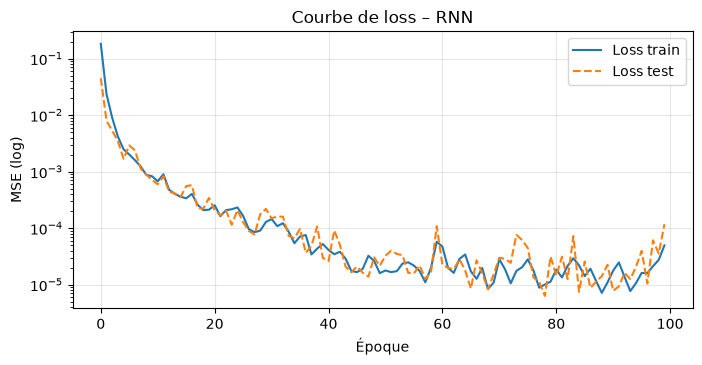

In [11]:
set_seed(SEED)
rnn_history = train_model(rnn_model, train_loader, X_test_t, y_test_t, epochs=100, lr=1e-2)
plot_loss(rnn_history, "RNN")

### Évaluation du RNN

On calcule la MSE sur le jeu de test, on trace les prédictions, puis on teste **une seule séquence** de `X_test` : le modèle prédit la valeur suivante qu'on compare à la vraie valeur.

MSE test (RNN) : 0.000118


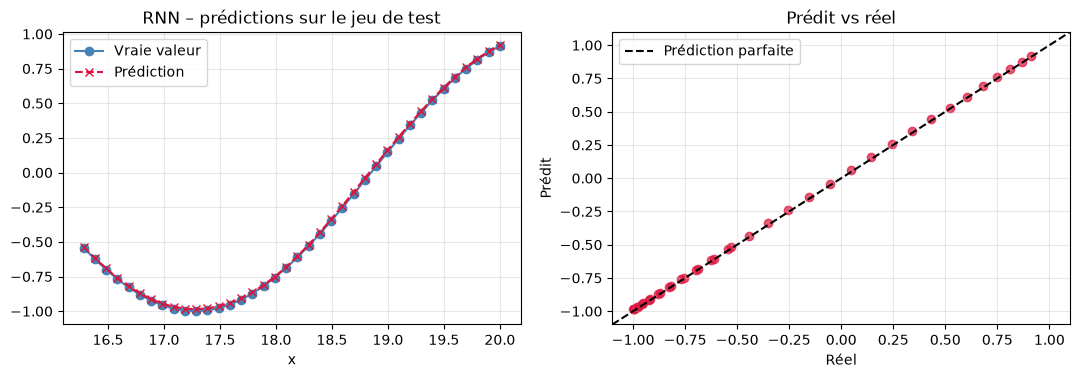

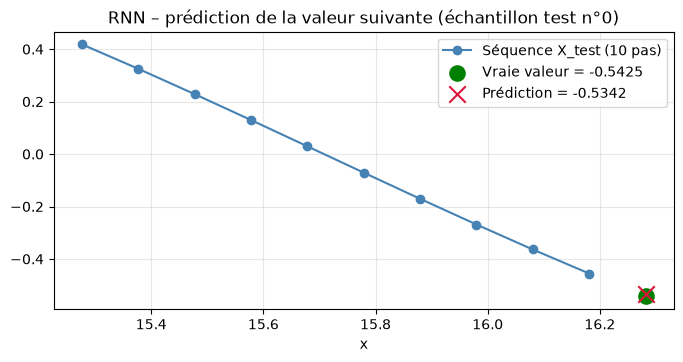

Vraie valeur : -0.54253 | Prédiction : -0.53424 | Erreur absolue : 0.00828


In [12]:
rnn_preds, rnn_mse = evaluate_model(rnn_model, X_test_t, y_test_t)
results["RNN"] = {"mse": rnn_mse, "params": count_parameters(rnn_model), "preds": rnn_preds}
print(f"MSE test (RNN) : {rnn_mse:.6f}")

plot_predictions(y_test, rnn_preds, "RNN")
plot_single_prediction(rnn_model, idx=0, title="RNN")

# 🧬 PARTIE 3 – LSTM (Long Short-Term Memory)

### Architecture

Le LSTM ajoute à l'état caché `h_t` une **cellule mémoire** `c_t` contrôlée par trois **portes** (*forget*, *input*, *output*) qui décident quoi oublier, quoi écrire et quoi exposer. Le gradient circule mieux le long de `c_t` → **meilleure mémoire à long terme**.

```
 h0 = 0, c0 = 0
      │
      ▼
 [LSTM]─(h1,c1)─[LSTM]─(h2,c2)─ ... ─[LSTM]─(h10,c10)
   ▲               ▲                      ▲
   x1              x2                     x10

 hn (batch, 16) ──►  Linear(16 → 1)  ──►  ŷ (batch, 1)
```

**Dimensions des tenseurs :**
```
Entrée x          : (B, 10, 1)
h0, c0            : (1, B, 16)  chacun, initialisés à zéro
Sorties out       : (B, 10, 16)
hn, cn            : (1, B, 16)  → hn[-1] : (B, 16)
Linear 16 → 1     : (B, 16) → (B, 1)
```

Un LSTM possède **4×** plus de paramètres qu'un RNN de même taille (4 blocs : 3 portes + candidat).

In [13]:
class LSTMModel(nn.Module):
    """LSTM (16 unités) -> dernier état caché -> Linear(16 -> 1)."""

    def __init__(self, input_size=1, hidden_size=16):
        super().__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x : (B, seq_len, 1)
        h0 = torch.zeros(1, x.size(0), self.hidden_size, device=x.device)  # h0 = 0
        c0 = torch.zeros(1, x.size(0), self.hidden_size, device=x.device)  # c0 = 0
        out, (hn, cn) = self.lstm(x, (h0, c0))   # out : (B, seq_len, 16) | hn, cn : (1, B, 16)
        return self.fc(hn[-1])                   # ŷ : (B, 1)


set_seed(SEED)
lstm_model = LSTMModel()
print(lstm_model)
print(f"\nNombre de paramètres entraînables (LSTM) : {count_parameters(lstm_model):,}")

LSTMModel(
  (lstm): LSTM(1, 16, batch_first=True)
  (fc): Linear(in_features=16, out_features=1, bias=True)
)

Nombre de paramètres entraînables (LSTM) : 1,233


Époque    1/100 | loss train = 0.316550 | loss test = 0.105657
Époque   20/100 | loss train = 0.000014 | loss test = 0.000010
Époque   40/100 | loss train = 0.000004 | loss test = 0.000004
Époque   60/100 | loss train = 0.000004 | loss test = 0.000003
Époque   80/100 | loss train = 0.000003 | loss test = 0.000002
Époque  100/100 | loss train = 0.000002 | loss test = 0.000003


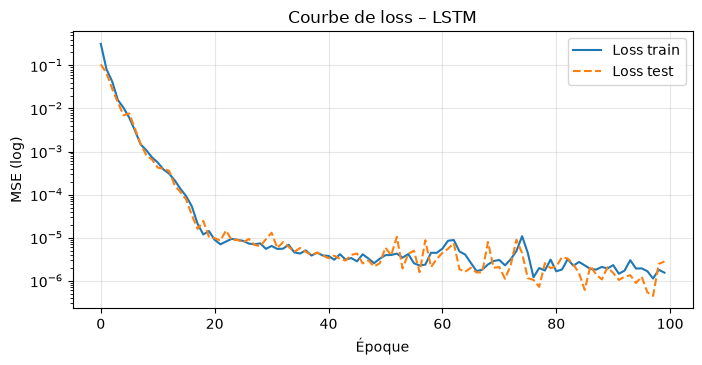

In [14]:
set_seed(SEED)
lstm_history = train_model(lstm_model, train_loader, X_test_t, y_test_t, epochs=100, lr=1e-2)
plot_loss(lstm_history, "LSTM")

MSE test (LSTM) : 0.000003


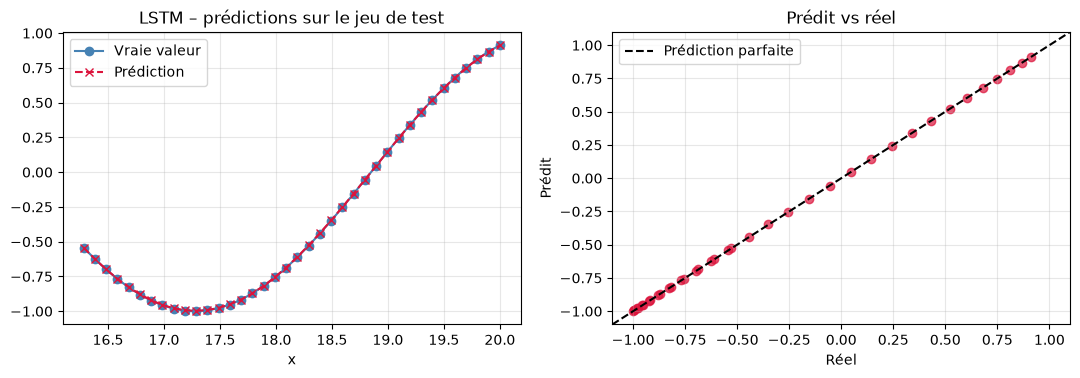

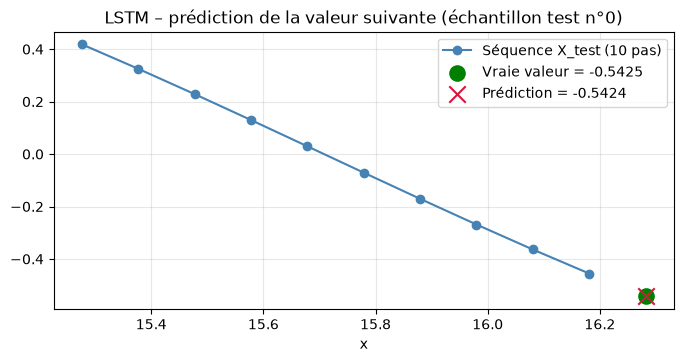

Vraie valeur : -0.54253 | Prédiction : -0.54245 | Erreur absolue : 0.00008


In [15]:
lstm_preds, lstm_mse = evaluate_model(lstm_model, X_test_t, y_test_t)
results["LSTM"] = {"mse": lstm_mse, "params": count_parameters(lstm_model), "preds": lstm_preds}
print(f"MSE test (LSTM) : {lstm_mse:.6f}")

plot_predictions(y_test, lstm_preds, "LSTM")
plot_single_prediction(lstm_model, idx=0, title="LSTM")

# ⚡ PARTIE 4 – Transformer (from scratch)

Le Transformer (*Attention Is All You Need*, 2017) abandonne la récurrence : **tous les pas de temps sont traités en parallèle** et chacun peut **regarder directement** n'importe quel autre grâce à l'**auto-attention**.

### Architecture à implémenter, bloc par bloc

```
 Entrées x1 … xn                         (B, n, 1)
        │
        ▼
 ① Projection linéaire 1 → 16            (B, n, 16)
        │                                  ┌─ Indices 0 … n-1             (n,)
        │                                  ▼
        │                           ② Embedding positionnel (nn.Embedding) (n, 16)
        ▼                                  │
 ③ ADDITION  (projection + embedding positionnel)                         (B, n, 16)
        │
        ├──────────────┐
        ▼              │ (résiduel)
 ④ Self-Attention      │
   multi-têtes (2 têtes, d_model = 16)
        ▼              │
   Add & LayerNorm ◄───┘                                                   (B, n, 16)
        │
        ├──────────────┐
        ▼              │ (résiduel)
 ⑤ Feed Forward        │
   16 → 32 → 16 (ReLU)
        ▼              │
   Add & LayerNorm ◄───┘                                                   (B, n, 16)
        │
        ▼
 ⑥ Dernière représentation  [:, -1, :]                                     (B, 16)
        │
        ▼
 ⑦ Linéaire 16 → 1  →  ŷ                                                   (B, 1)
```

### L'auto-attention multi-têtes en quelques lignes

Pour chaque position, on calcule trois vecteurs : **Q** (*query* : ce que je cherche), **K** (*key* : ce que j'offre), **V** (*value* : ce que je transmets).

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Avec **2 têtes** et `d_model = 16`, chaque tête travaille dans un sous-espace de `d_k = 16/2 = 8` dimensions ; les têtes sont ensuite concaténées puis projetées.

```
 x : (B, T, 16) ─► W_q, W_k, W_v ─► (B, T, 16) ─► découpe en 2 têtes ─► (B, 2, T, 8)
 scores = Q·Kᵀ / √8     : (B, 2, T, T)       ← qui regarde qui ?
 poids  = softmax(scores): (B, 2, T, T)       ← chaque ligne somme à 1
 sortie = poids · V      : (B, 2, T, 8) ─► concaténation ─► (B, T, 16) ─► W_o ─► (B, T, 16)
```

Ici l'attention est **bidirectionnelle** (`causal=False`) : on a le droit de regarder les 10 valeurs passées entières. Le paramètre `causal=True` (masque triangulaire) sera réutilisé dans la partie 5 (GPT).

In [16]:
class MultiHeadSelfAttention(nn.Module):
    """Auto-attention multi-têtes implémentée à la main.

    Entrée / sortie : (B, T, d_model)
    causal=False -> chaque position voit toute la séquence (encodeur)
    causal=True  -> masque triangulaire : chaque position ne voit que le passé (décodeur GPT)
    """

    def __init__(self, d_model=16, n_heads=2, causal=False):
        super().__init__()
        assert d_model % n_heads == 0, "d_model doit être divisible par n_heads"
        self.d_model, self.n_heads = d_model, n_heads
        self.d_head = d_model // n_heads          # dimension par tête (16 / 2 = 8)
        self.causal = causal
        # Projections linéaires pour Q, K, V et projection de sortie
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.last_attn = None                     # on garde les poids pour les visualiser

    def forward(self, x):
        B, T, D = x.shape                         # x : (B, T, d_model)

        # 1) Projections puis découpe en têtes : (B, T, D) -> (B, n_heads, T, d_head)
        def split_heads(t):
            return t.view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        q, k, v = split_heads(self.W_q(x)), split_heads(self.W_k(x)), split_heads(self.W_v(x))

        # 2) Scores d'attention : (B, n_heads, T, T), normalisés par √d_head
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d_head)

        # 3) (Optionnel) masque causal : on interdit de regarder le futur
        if self.causal:
            mask = torch.tril(torch.ones(T, T, device=x.device, dtype=torch.bool))
            scores = scores.masked_fill(~mask, float("-inf"))

        # 4) Softmax -> poids d'attention (chaque ligne somme à 1)
        attn = F.softmax(scores, dim=-1)
        self.last_attn = attn.detach()

        # 5) Moyenne pondérée des valeurs, puis recombinaison des têtes
        out = attn @ v                                            # (B, n_heads, T, d_head)
        out = out.transpose(1, 2).contiguous().view(B, T, D)      # (B, T, d_model)
        return self.W_o(out)


# Petit test de dimensions
_mha = MultiHeadSelfAttention(16, 2)
_x = torch.randn(4, 10, 16)
print("Entrée :", tuple(_x.shape), "-> Sortie :", tuple(_mha(_x).shape),
      "| Poids d'attention :", tuple(_mha.last_attn.shape))

Entrée : (4, 10, 16) -> Sortie : (4, 10, 16) | Poids d'attention : (4, 2, 10, 10)


In [17]:
class TimeSeriesTransformer(nn.Module):
    """Transformer (1 bloc encodeur) pour la prédiction d'une série temporelle.

    x (B, n, 1) -> Linear(1->16) + Embedding positionnel -> Self-Attention + Add&Norm
                -> FeedForward(16->32->16) + Add&Norm -> [:, -1, :] -> Linear(16->1)
    """

    def __init__(self, seq_len=10, d_model=16, n_heads=2, d_ff=32):
        super().__init__()
        # ① Projection linéaire des valeurs scalaires vers l'espace de dimension d_model
        self.input_proj = nn.Linear(1, d_model)
        # ② Embedding positionnel appris : une ligne par position 0 … seq_len-1
        self.pos_emb = nn.Embedding(seq_len, d_model)
        # ④ Self-attention multi-têtes + LayerNorm
        self.attn = MultiHeadSelfAttention(d_model, n_heads, causal=False)
        self.norm1 = nn.LayerNorm(d_model)
        # ⑤ Feed Forward 16 -> 32 -> 16 (ReLU) + LayerNorm
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
        self.norm2 = nn.LayerNorm(d_model)
        # ⑦ Tête de régression
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        B, T, _ = x.shape                                    # x : (B, T, 1)
        positions = torch.arange(T, device=x.device)         # indices 0 … T-1 : (T,)

        # ①+②+③ projection + embedding positionnel (broadcast sur le batch)
        h = self.input_proj(x) + self.pos_emb(positions)     # (B,T,16) + (T,16) -> (B,T,16)

        # ④ Self-attention avec connexion résiduelle puis LayerNorm
        h = self.norm1(h + self.attn(h))                     # (B, T, 16)

        # ⑤ Feed Forward avec connexion résiduelle puis LayerNorm
        h = self.norm2(h + self.ff(h))                       # (B, T, 16)

        # ⑥ On garde uniquement la représentation du DERNIER pas de temps
        last = h[:, -1, :]                                   # (B, 16)

        # ⑦ Régression finale
        return self.fc(last)                                 # ŷ : (B, 1)


set_seed(SEED)
transformer_model = TimeSeriesTransformer(seq_len=SEQ_LEN)
print(transformer_model)
print(f"\nNombre de paramètres entraînables (Transformer) : {count_parameters(transformer_model):,}")

# Vérification des dimensions sur un batch
with torch.no_grad():
    print("Sortie sur un batch :", tuple(transformer_model(xb).shape), "(attendu : (16, 1))")

TimeSeriesTransformer(
  (input_proj): Linear(in_features=1, out_features=16, bias=True)
  (pos_emb): Embedding(10, 16)
  (attn): MultiHeadSelfAttention(
    (W_q): Linear(in_features=16, out_features=16, bias=True)
    (W_k): Linear(in_features=16, out_features=16, bias=True)
    (W_v): Linear(in_features=16, out_features=16, bias=True)
    (W_o): Linear(in_features=16, out_features=16, bias=True)
  )
  (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
  (ff): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
  )
  (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
  (fc): Linear(in_features=16, out_features=1, bias=True)
)

Nombre de paramètres entraînables (Transformer) : 2,433
Sortie sur un batch : (16, 1) (attendu : (16, 1))


### Entraînement du Transformer

Le Transformer a davantage de paramètres à ajuster et une dynamique d'optimisation un peu différente : on utilise un taux d'apprentissage plus faible (`3e-3`) et un peu plus d'époques.

Époque    1/150 | loss train = 0.360542 | loss test = 0.121976
Époque   25/150 | loss train = 0.000371 | loss test = 0.000365
Époque   50/150 | loss train = 0.000030 | loss test = 0.000032
Époque   75/150 | loss train = 0.000061 | loss test = 0.000171
Époque  100/150 | loss train = 0.000009 | loss test = 0.000017
Époque  125/150 | loss train = 0.000015 | loss test = 0.000015
Époque  150/150 | loss train = 0.000072 | loss test = 0.000056


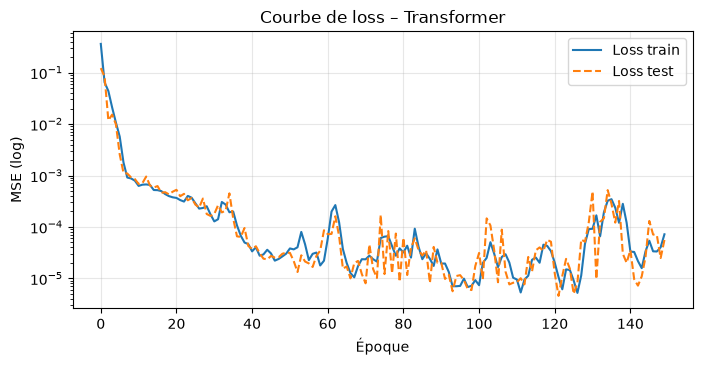

In [18]:
set_seed(SEED)
tr_history = train_model(transformer_model, train_loader, X_test_t, y_test_t, epochs=150, lr=3e-3, verbose_every=25)
plot_loss(tr_history, "Transformer")

MSE test (Transformer) : 0.000056


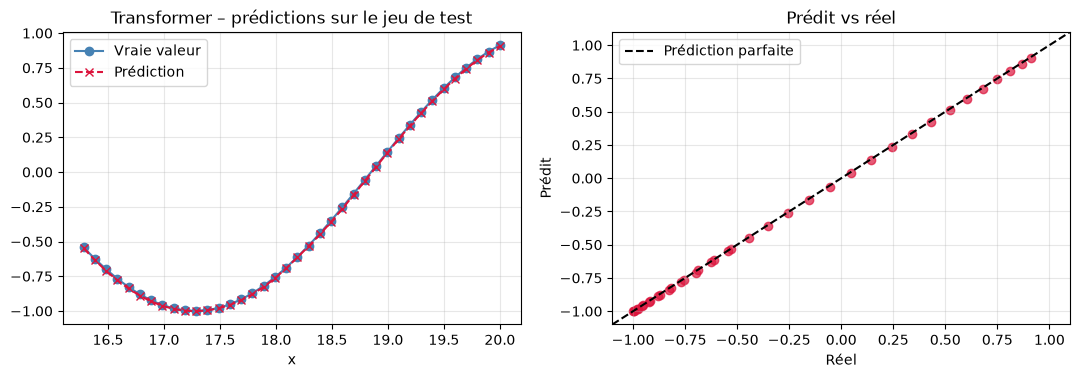

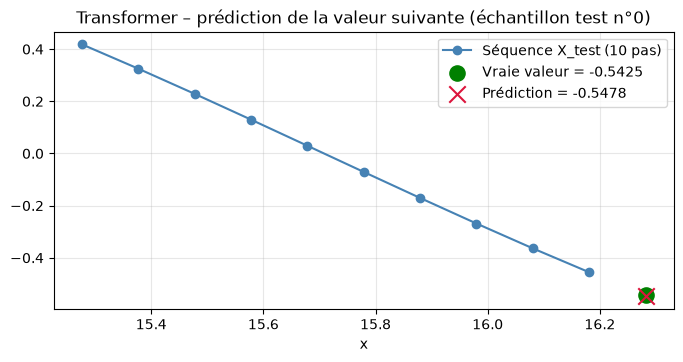

Vraie valeur : -0.54253 | Prédiction : -0.54785 | Erreur absolue : 0.00532


In [19]:
tr_preds, tr_mse = evaluate_model(transformer_model, X_test_t, y_test_t)
results["Transformer"] = {"mse": tr_mse, "params": count_parameters(transformer_model), "preds": tr_preds}
print(f"MSE test (Transformer) : {tr_mse:.6f}")

plot_predictions(y_test, tr_preds, "Transformer")
plot_single_prediction(transformer_model, idx=0, title="Transformer")

### 🔍 Visualiser l'attention du Transformer

Les poids d'attention montrent **quels pas de temps** le modèle regarde. Chaque ligne = une position *requête* ; chaque colonne = une position *clé* regardée. Ici, la dernière ligne (position 10, celle utilisée pour la prédiction) est la plus importante.

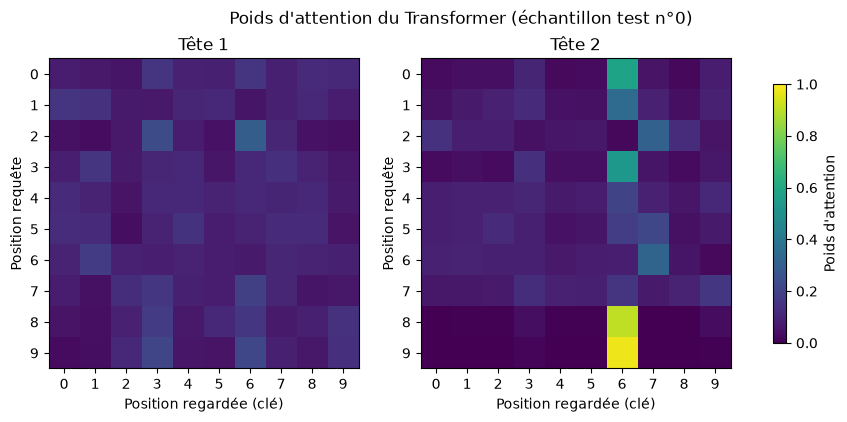

In [20]:
# Passe avant sur un seul échantillon pour récupérer les poids d'attention
transformer_model.eval()
with torch.no_grad():
    _ = transformer_model(X_test_t[0:1].to(device))
attn = transformer_model.attn.last_attn[0].cpu()    # (n_heads, T, T)

fig, axes = plt.subplots(1, attn.size(0), figsize=(11, 4.2))
for h, ax in enumerate(axes):
    im = ax.imshow(attn[h].numpy(), cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"Tête {h + 1}")
    ax.set_xlabel("Position regardée (clé)"); ax.set_ylabel("Position requête")
    ax.set_xticks(range(SEQ_LEN)); ax.set_yticks(range(SEQ_LEN))
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="Poids d'attention")
plt.suptitle("Poids d'attention du Transformer (échantillon test n°0)")
plt.show()

## 4.bis – Comparaison RNN vs LSTM vs Transformer

Tableau des **MSE sur le jeu de test**, nombre de paramètres, puis superposition des prédictions des trois modèles.

> ℹ️ Sur une tâche aussi simple (sinus pur, 10 pas de temps), les trois modèles réussissent bien : les différences se creusent surtout sur des séquences **longues** et **complexes**. Les valeurs exactes peuvent varier légèrement d'une exécution à l'autre selon le matériel.

,Modèle,Paramètres,MSE test
0,LSTM,1233,0.000003
1,Transformer,2433,0.000056
2,RNN,321,0.000118


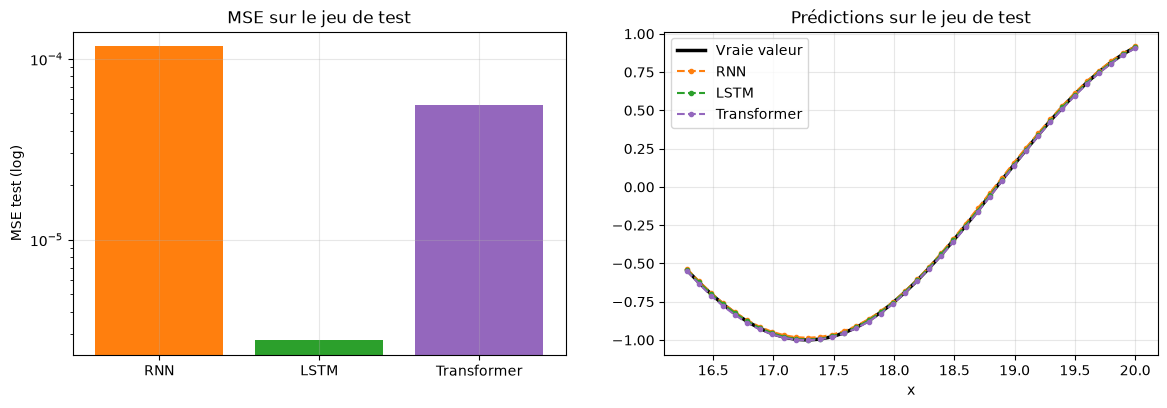

In [21]:
from IPython.display import display

# ---------- Tableau récapitulatif ----------
df = pd.DataFrame({
    "Modèle": list(results.keys()),
    "Paramètres": [r["params"] for r in results.values()],
    "MSE test": [r["mse"] for r in results.values()],
}).sort_values("MSE test").reset_index(drop=True)
df["MSE test"] = df["MSE test"].map(lambda v: f"{v:.6f}")
display(df)

# ---------- Graphiques ----------
colors = {"RNN": "tab:orange", "LSTM": "tab:green", "Transformer": "tab:purple"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# (a) Barres des MSE (échelle log car les écarts peuvent être grands)
names = list(results.keys())
axes[0].bar(names, [results[n]["mse"] for n in names], color=[colors[n] for n in names])
axes[0].set_yscale("log"); axes[0].set_ylabel("MSE test (log)")
axes[0].set_title("MSE sur le jeu de test")

# (b) Prédictions superposées
axes[1].plot(x_targets_test, y_test, "k-", linewidth=2.5, label="Vraie valeur")
for n in names:
    axes[1].plot(x_targets_test, results[n]["preds"], "--", marker=".", color=colors[n], label=n)
axes[1].set_title("Prédictions sur le jeu de test"); axes[1].set_xlabel("x"); axes[1].legend()
plt.show()

# 🤖 PARTIE 5 – GPT (décodeur, attention causale)

### Qu'est-ce que GPT ?

**GPT** = **G**enerative **P**re-trained **T**ransformer.

- **Generative** : le modèle *génère* du texte, un token à la fois.
- **Pre-trained** : il est d'abord pré-entraîné sur d'énormes corpus de texte (tâche : *prédire le prochain token*), puis éventuellement affiné.
- **Transformer** : il empile des blocs **décodeur** (auto-attention + feed-forward).

La clé est l'**attention causale** : pour prédire le token à la position *t*, le modèle ne doit voir que les tokens `≤ t`, jamais le futur. On y parvient avec un **masque triangulaire inférieur** appliqué aux scores d'attention avant le softmax : les positions interdites reçoivent `-∞`, donc un poids de **0** après le softmax.

```
 Texte :  "Artificial intelligence can help people"
 Tâche :  chaque token prédit le SUIVANT

   Artificial  →  intelligence
   intelligence → can
   can         →  help
   help        →  people              Masque causal (1 = autorisé, 0 = interdit)

                                          Art. int. can  help ppl
                                   Art.  [ 1    0    0    0    0 ]
                                   int.  [ 1    1    0    0    0 ]
                                   can   [ 1    1    1    0    0 ]
                                   help  [ 1    1    1    1    0 ]
                                   ppl   [ 1    1    1    1    1 ]
```

**Dimensions dans un décodeur GPT :**
```
Tokens (B, T) → Embedding token (B, T, d) + Embedding position (T, d) → (B, T, d)
   → N × [ Attention causale + Add&Norm → Feed-Forward + Add&Norm ]   (B, T, d)
   → LayerNorm → Linear(d → vocab)                                    (B, T, V)   # logits
   → softmax sur le dernier token → distribution du prochain token   (B, V)
```

#### 5.1 Visualiser le masque causal

Nous prenons 5 tokens, des scores d'attention aléatoires, et nous montrons l'effet du masque : (a) le masque, (b) les scores bruts, (c) les poids après masquage et softmax.

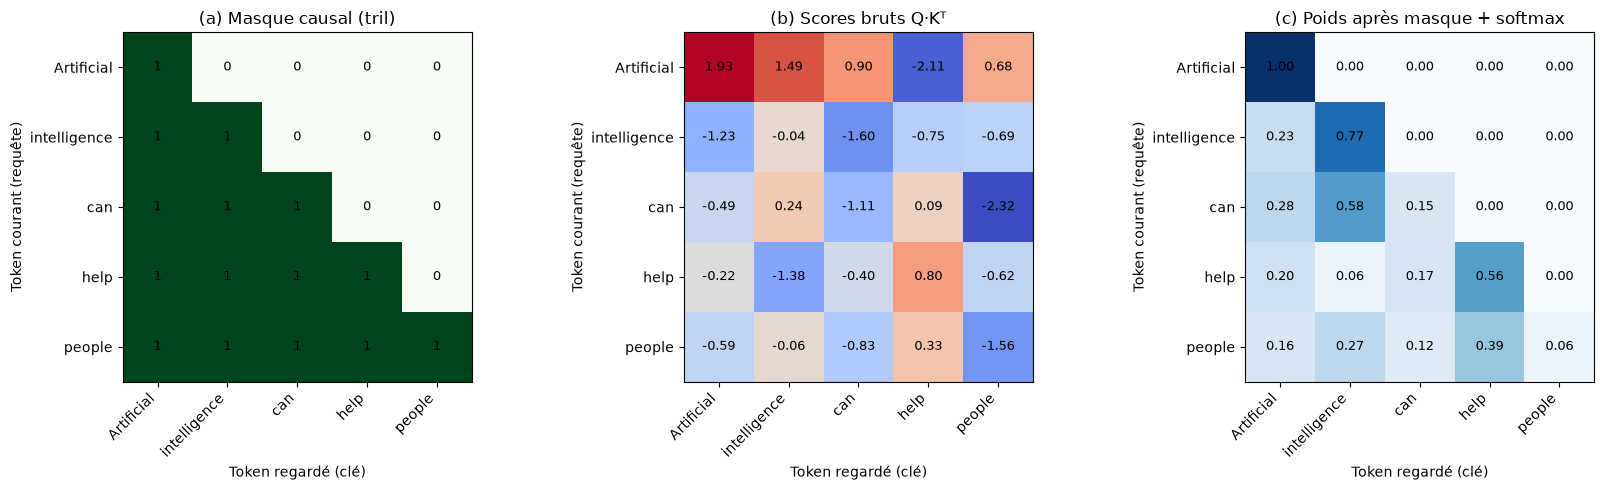

Somme de chaque ligne (doit être 1) : [1. 1. 1. 1. 1.]


In [22]:
tokens = ["Artificial", "intelligence", "can", "help", "people"]
T = len(tokens)

set_seed(SEED)
scores = torch.randn(T, T)                       # scores bruts Q·Kᵀ (fictifs)
causal_mask = torch.tril(torch.ones(T, T))       # 1 = autorisé, 0 = interdit (futur)
masked_scores = scores.masked_fill(causal_mask == 0, float("-inf"))
weights = F.softmax(masked_scores, dim=-1)       # -inf -> poids 0 ; chaque ligne somme à 1


def draw_matrix(ax, mat, title, cmap, fmt="{:.2f}", vmin=None, vmax=None):
    """Affiche une matrice T×T annotée, avec les tokens en axes."""
    ax.imshow(mat, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(T)); ax.set_xticklabels(tokens, rotation=45, ha="right")
    ax.set_yticks(range(T)); ax.set_yticklabels(tokens)
    ax.set_title(title); ax.grid(False)
    ax.set_xlabel("Token regardé (clé)"); ax.set_ylabel("Token courant (requête)")
    for i in range(T):
        for j in range(T):
            ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center", fontsize=9)


fig, axes = plt.subplots(1, 3, figsize=(17, 5))
draw_matrix(axes[0], causal_mask.numpy(), "(a) Masque causal (tril)", "Greens", fmt="{:.0f}", vmin=0, vmax=1)
draw_matrix(axes[1], scores.numpy(), "(b) Scores bruts Q·Kᵀ", "coolwarm")
draw_matrix(axes[2], weights.numpy(), "(c) Poids après masque + softmax", "Blues", vmin=0, vmax=1)
plt.tight_layout(); plt.show()

print("Somme de chaque ligne (doit être 1) :", weights.sum(dim=-1).numpy().round(3))

#### 5.2 Un mini-GPT construit à la main (niveau caractères)

Nous réutilisons notre `MultiHeadSelfAttention` avec `causal=True` pour assembler un **mini-GPT**. Il est entraîné sur un tout petit corpus de phrases (niveau *caractère*), donc il ne « comprend » pas vraiment le langage : c'est une démonstration **pédagogique** de l'architecture et de la génération auto-régressive.

*(Remarque : les GPT modernes utilisent généralement un LayerNorm placé **avant** chaque sous-couche, « pre-LN », ce que fait ce mini-GPT.)*

**Génération auto-régressive :**
```
"Artificial intelligence can"  → prédit " " → on l'ajoute au texte
"Artificial intelligence can " → prédit "h" → on l'ajoute
...                            → et ainsi de suite
```

In [23]:
# ---------------------------------------------------------------
# Corpus minuscule (répété pour avoir assez de données) et tokenisation par caractère
# ---------------------------------------------------------------
sentences = [
    "Artificial intelligence can help people and organizations.",
    "Artificial intelligence can improve healthcare and education.",
    "Transformers use attention to understand language.",
    "Language models can predict the next word in a sentence.",
    "Deep learning can find patterns in large amounts of data.",
]
corpus = " ".join(sentences) * 20

chars = sorted(set(corpus))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}          # caractère -> indice
itos = {i: c for c, i in stoi.items()}              # indice -> caractère
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)

data = torch.tensor(encode(corpus), dtype=torch.long)
print(f"Taille du corpus : {len(data)} caractères | vocabulaire : {vocab_size} caractères")

# Hyperparamètres du mini-GPT
BLOCK_SIZE = 32      # longueur maximale du contexte
GPT_BATCH  = 32
D_MODEL    = 64
N_HEADS    = 4
N_LAYERS   = 2


def get_batch(batch_size=GPT_BATCH, block_size=BLOCK_SIZE):
    """Tire des fenêtres aléatoires. y est x décalé d'un cran (prédire le caractère suivant)."""
    ix = torch.randint(len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i : i + block_size] for i in ix])             # (B, T)
    y = torch.stack([data[i + 1 : i + block_size + 1] for i in ix])     # (B, T)
    return x.to(device), y.to(device)

Taille du corpus : 5720 caractères | vocabulaire : 27 caractères


In [24]:
class GPTBlock(nn.Module):
    """Bloc décodeur : LayerNorm -> attention causale -> résiduel -> LayerNorm -> FFN -> résiduel."""

    def __init__(self, d_model, n_heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, n_heads, causal=True)   # <-- masque causal
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x):                        # x : (B, T, d_model)
        x = x + self.attn(self.ln1(x))           # résiduel autour de l'attention
        x = x + self.ffn(self.ln2(x))            # résiduel autour du feed-forward
        return x


class MiniGPT(nn.Module):
    """Mini-GPT : embeddings -> N blocs décodeur -> LayerNorm -> Linear(d_model -> vocab)."""

    def __init__(self, vocab_size, block_size, d_model=64, n_heads=4, n_layers=2):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)      # (B, T) -> (B, T, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)      # positions 0 … T-1
        self.blocks = nn.Sequential(*[GPTBlock(d_model, n_heads) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)            # logits sur le vocabulaire

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)             # (B, T, d_model)
        x = self.blocks(x)                                    # (B, T, d_model)
        logits = self.head(self.ln_f(x))                      # (B, T, vocab)
        loss = None
        if targets is not None:                               # entropie croisée sur tous les tokens
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=40, temperature=0.7):
        """Génération auto-régressive : on ajoute un token à la fois."""
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]                   # on tronque au contexte max
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature                # dernier token : (B, vocab)
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)      # échantillonnage
            idx = torch.cat([idx, next_id], dim=1)                 # (B, T+1)
        return idx


set_seed(SEED)
mini_gpt = MiniGPT(vocab_size, BLOCK_SIZE, D_MODEL, N_HEADS, N_LAYERS).to(device)
print(f"Nombre de paramètres entraînables (mini-GPT) : {count_parameters(mini_gpt):,}")

Nombre de paramètres entraînables (mini-GPT) : 105,627


#### Entraînement du mini-GPT

Perte : **entropie croisée** (classification du prochain caractère parmi `vocab_size`), optimiseur Adam.

Étape    1/600 | loss = 3.3732
Étape  100/600 | loss = 0.3921
Étape  200/600 | loss = 0.1334
Étape  300/600 | loss = 0.1094
Étape  400/600 | loss = 0.1291
Étape  500/600 | loss = 0.1065
Étape  600/600 | loss = 0.1122


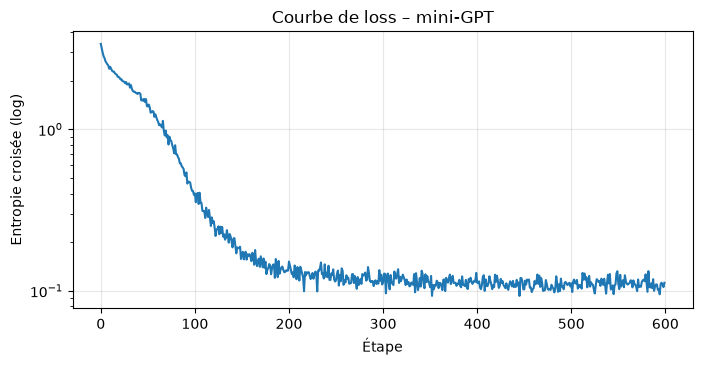

In [25]:
set_seed(SEED)
optimizer = torch.optim.Adam(mini_gpt.parameters(), lr=3e-3)
GPT_STEPS = 600
gpt_losses = []

mini_gpt.train()
for step in range(1, GPT_STEPS + 1):
    xb_gpt, yb_gpt = get_batch()
    _, loss = mini_gpt(xb_gpt, yb_gpt)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    gpt_losses.append(loss.item())
    if step == 1 or step % 100 == 0:
        print(f"Étape {step:4d}/{GPT_STEPS} | loss = {loss.item():.4f}")

plt.figure(figsize=(8, 3.6))
plt.plot(gpt_losses); plt.yscale("log")
plt.xlabel("Étape"); plt.ylabel("Entropie croisée (log)")
plt.title("Courbe de loss – mini-GPT"); plt.show()

#### Génération + vérification de la causalité

1. On génère la suite de `"Artificial intelligence can"`.
2. On **prouve** que le modèle est causal : si on modifie le **dernier** token, les sorties des positions **précédentes** ne doivent pas changer.

In [26]:
# ---------- 1) Génération ----------
set_seed(SEED)
prompt = "Artificial intelligence can"
start = torch.tensor([encode(prompt)], dtype=torch.long, device=device)   # (1, T)
generated = mini_gpt.generate(start, max_new_tokens=40, temperature=0.5)
print("Prompt  :", prompt)
print("Mini-GPT:", decode(generated[0].tolist()))

# ---------- 2) Test de causalité ----------
mini_gpt.eval()
with torch.no_grad():
    ids1 = torch.randint(0, vocab_size, (1, 12), device=device)
    ids2 = ids1.clone()
    ids2[0, -1] = (ids2[0, -1] + 1) % vocab_size           # on change uniquement le DERNIER token
    logits1, _ = mini_gpt(ids1)
    logits2, _ = mini_gpt(ids2)

same_before = torch.allclose(logits1[:, :-1], logits2[:, :-1], atol=1e-5)   # positions 0…10
same_last = torch.allclose(logits1[:, -1], logits2[:, -1], atol=1e-5)       # position 11
print(f"\nSorties des positions précédentes inchangées : {same_before}   (attendu : True)")
print(f"Sortie de la dernière position inchangée     : {same_last}  (attendu : False)")

Prompt  : Artificial intelligence can
Mini-GPT: Artificial intelligence can help people and organizations. Artifici

Sorties des positions précédentes inchangées : True   (attendu : True)
Sortie de la dernière position inchangée     : False  (attendu : False)


#### 5.3 GPT-2 pré-entraîné (Hugging Face)

Utilisons maintenant un **vrai** modèle pré-entraîné : **GPT-2** (≈ 124 millions de paramètres, entraîné sur des millions de pages web). Avec le `pipeline("text-generation")` de Hugging Face, il complète le texte ; nous affichons aussi les **5 tokens les plus probables** pour le prochain mot.

*(Le premier lancement télécharge le modèle ≈ 500 Mo : patientez un peu.)*

In [3]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"                 # désactive le transfert Xet (source des blocages)
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"    # supprime l'avertissement Windows
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "60"           # échoue au lieu de rester bloqué
# os.environ["HF_TOKEN"] = "hf_votre_token"            # facultatif : limites de débit plus larges

In [2]:
import shutil, os
shutil.rmtree(os.path.expanduser("~/.cache/huggingface/hub/models--gpt2"), ignore_errors=True)

In [ ]:
from transformers import pipeline, set_seed as hf_set_seed

MODEL_NAME = "distilgpt2"   # version allégée de GPT-2 (~330 Mo)

hf_set_seed(SEED)
generator = pipeline("text-generation", model=MODEL_NAME,
                     device=0 if torch.cuda.is_available() else -1)

prompt = "Artificial intelligence can"

# (a) Décodage glouton (greedy) : toujours le token le plus probable -> résultat déterministe
out_greedy = generator(prompt, max_new_tokens=20, do_sample=False, pad_token_id=50256)
print("🔹 Greedy  :", out_greedy[0]["generated_text"])

# (b) Échantillonnage (sampling) avec température : plus varié, plus « créatif »
hf_set_seed(SEED)
out_sample = generator(prompt, max_new_tokens=20, do_sample=True, temperature=0.8, top_k=50,
                       num_return_sequences=3, pad_token_id=50256)
for i, o in enumerate(out_sample, 1):
    print(f"🔸 Sample {i}:", o["generated_text"].replace("\n", " "))

print(f"\nParamètres de {MODEL_NAME} : {sum(p.numel() for p in generator.model.parameters()):,}")

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

🔹 Greedy  : Artificial intelligence can be used to create a new kind of artificial intelligence.









🔸 Sample 1: Artificial intelligence can be a powerful tool to solve problems in the human realm.
🔸 Sample 2: Artificial intelligence can be manipulated to create artificial intelligence, for example. In the United States, artificial intelligence can be used
🔸 Sample 3: Artificial intelligence can be used more than one day. It‡s a tool which will allow users to use it

Paramètres de distilgpt2 : 81,912,576


Prompt : 'Artificial intelligence can' | tokens : ['Art', 'ificial', 'Ġintelligence', 'Ġcan']
            be : 20.856%
          help : 6.738%
          also : 3.188%
          make : 2.546%
        create : 2.166%


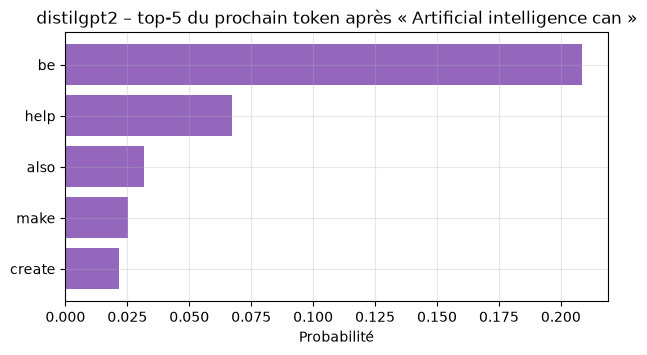

In [14]:
# ---------------------------------------------------------------
# Top-5 des tokens suivants les plus probables selon GPT-2
# ---------------------------------------------------------------
tok = generator.tokenizer
gpt2 = generator.model.eval()

inputs = tok(prompt, return_tensors="pt").to(gpt2.device)     # input_ids : (1, T)
with torch.no_grad():
    logits = gpt2(**inputs).logits                            # (1, T, vocab=50257)

probs = F.softmax(logits[0, -1], dim=-1)                      # distribution du PROCHAIN token : (vocab,)
top = torch.topk(probs, 5)
top_tokens = [tok.decode([i]).strip() or "␣" for i in top.indices.tolist()]
top_probs = top.values.cpu().numpy()

print(f"Prompt : '{prompt}' | tokens : {tok.convert_ids_to_tokens(inputs['input_ids'][0])}")
for t, p in zip(top_tokens, top_probs):
    print(f"  {t:>12s} : {p:.3%}")

plt.figure(figsize=(7, 3.5))
plt.barh(top_tokens[::-1], top_probs[::-1], color="tab:purple")
plt.xlabel("Probabilité"); plt.title(f"distilgpt2 – top-5 du prochain token après « {prompt} »")
plt.show()

# 🎭 PARTIE 6 – BERT (encodeur, attention bidirectionnelle)

### Qu'est-ce que BERT ?

**BERT** = **B**idirectional **E**ncoder **R**epresentations from **T**ransformers (Google, 2018).

- Il n'utilise que la partie **encodeur** du Transformer.
- Son attention est **bidirectionnelle** : chaque token voit **tout le contexte, à gauche ET à droite** (pas de masque causal).
- Pré-entraînement par **Masked Language Modeling (MLM)** : on cache ~15 % des mots avec `[MASK]` et le modèle doit les retrouver. Il apprend aussi la *Next Sentence Prediction* (NSP).
- Il ne *génère* pas de texte : il produit des **représentations contextuelles** utiles pour la classification, la NER, le question-réponse, la recherche sémantique…

```
 Phrase :  [MASK]   est   la   capitale   du   Maroc   .
              ▲  ◄──────────────────────────────────────┐
              │   chaque token voit TOUS les autres     │
              └─────────────── attention bidirectionnelle
 BERT prédit : « Rabat »

 Attention BERT (tout autorisé)         Attention GPT (triangulaire)
   [ 1 1 1 1 1 ]                          [ 1 0 0 0 0 ]
   [ 1 1 1 1 1 ]                          [ 1 1 0 0 0 ]
   [ 1 1 1 1 1 ]                          [ 1 1 1 0 0 ]
   [ 1 1 1 1 1 ]                          [ 1 1 1 1 0 ]
   [ 1 1 1 1 1 ]                          [ 1 1 1 1 1 ]
```

**Dimensions :** `(B, T)` tokens → `(B, T, 768)` représentations → tête MLM `(B, T, vocab)` → on lit la position du `[MASK]`.

#### 6.1 Comparer visuellement les deux types d'attention

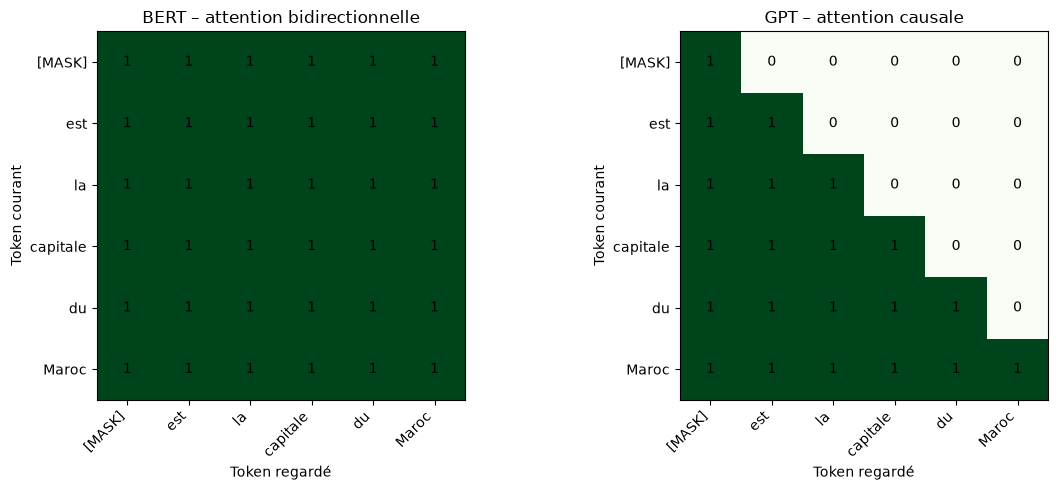

In [15]:
tokens_b = ["[MASK]", "est", "la", "capitale", "du", "Maroc"]
Tb = len(tokens_b)
full_mask = torch.ones(Tb, Tb)                       # BERT : tout est autorisé
causal_b = torch.tril(torch.ones(Tb, Tb))            # GPT  : triangulaire inférieur

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, mat, title in zip(axes, [full_mask, causal_b],
                          ["BERT – attention bidirectionnelle", "GPT – attention causale"]):
    ax.imshow(mat.numpy(), cmap="Greens", vmin=0, vmax=1)
    ax.set_xticks(range(Tb)); ax.set_xticklabels(tokens_b, rotation=45, ha="right")
    ax.set_yticks(range(Tb)); ax.set_yticklabels(tokens_b)
    ax.set_title(title); ax.grid(False)
    ax.set_xlabel("Token regardé"); ax.set_ylabel("Token courant")
    for i in range(Tb):
        for j in range(Tb):
            ax.text(j, i, int(mat[i, j].item()), ha="center", va="center")
plt.tight_layout(); plt.show()

#### 6.2 Pipeline `fill-mask` avec BERT multilingue

On utilise `bert-base-multilingual-cased` (≈ 178 M de paramètres, 104 langues dont le français et l'arabe). Le pipeline `fill-mask` renvoie les `top_k` mots les plus probables à la place de `[MASK]`, avec leur **score** (probabilité).

> 💡 Pour de meilleurs résultats en français, vous pouvez essayer `camembert-base` (dont le token de masque est `<mask>` : le code ci-dessous le gère automatiquement) ; pour l'arabe : `aubmindlab/bert-base-arabertv2`.

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Token de masque du modèle : [MASK]
Paramètres de BERT : 177,974,523

📝 la capitale du Maroc est [MASK] .
  1. Casablanca      score = 0.5941  →  la capitale du Maroc est Casablanca.
  2. Rabat           score = 0.1689  →  la capitale du Maroc est Rabat.
  3. Metz            score = 0.0281  →  la capitale du Maroc est Metz.
  4. Alger           score = 0.0124  →  la capitale du Maroc est Alger.
  5. Dakar           score = 0.0113  →  la capitale du Maroc est Dakar.


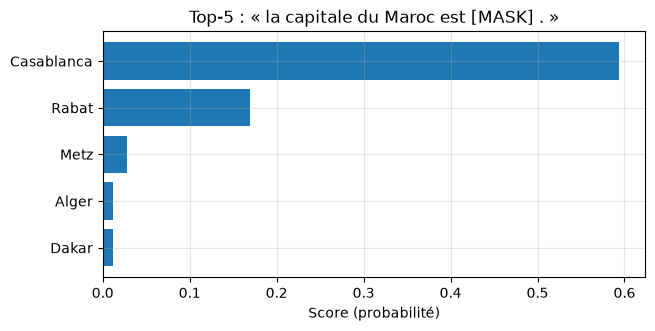

In [16]:
unmasker = pipeline("fill-mask", model="bert-base-multilingual-cased", top_k=5,
                    device=0 if torch.cuda.is_available() else -1)
print("Token de masque du modèle :", unmasker.tokenizer.mask_token)
print(f"Paramètres de BERT : {sum(p.numel() for p in unmasker.model.parameters()):,}")


def show_fill_mask(text, top_k=5):
    """Affiche et trace les top-k prédictions pour le [MASK] de `text`."""
    # On remplace [MASK] par le vrai token de masque du modèle (utile pour CamemBERT, RoBERTa…)
    text_model = text.replace("[MASK]", unmasker.tokenizer.mask_token)
    preds = unmasker(text_model, top_k=top_k)             # liste de dicts : token_str, score, sequence

    print(f"\n📝 {text}")
    for rank, p in enumerate(preds, 1):
        print(f"  {rank}. {p['token_str']:<15s} score = {p['score']:.4f}  →  {p['sequence']}")

    plt.figure(figsize=(7, 3.2))
    plt.barh([p["token_str"] for p in preds][::-1], [p["score"] for p in preds][::-1], color="tab:blue")
    plt.xlabel("Score (probabilité)"); plt.title(f"Top-{top_k} : « {text} »")
    plt.show()
    return preds


# Exemple de l'énoncé : on s'attend à « Rabat »
_ = show_fill_mask("la capitale du Maroc est [MASK] .")

**Pourqoi BERT affiche Casablanca au lieu de Rabat ?**

**Casablanca est beaucoup plus cité que Rabat. C’est la plus grande ville et la capitale économique, donc elle apparaît bien plus souvent à côté de « Maroc » dans les textes. Le modèle a probablement appris le motif « [Ville] … du Maroc », pas « capitale = Rabat ».**


📝 Casablanca est la plus grande ville du [MASK].
  1. Casablanca      score = 0.6249  →  Casablanca est la plus grande ville du Casablanca.
  2. Maroc           score = 0.3146  →  Casablanca est la plus grande ville du Maroc.
  3. monde           score = 0.0075  →  Casablanca est la plus grande ville du monde.
  4. pays            score = 0.0074  →  Casablanca est la plus grande ville du pays.
  5. port            score = 0.0037  →  Casablanca est la plus grande ville du port.


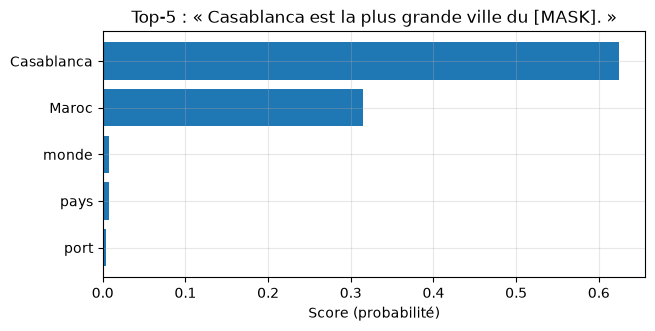


📝 Paris is the capital of [MASK].
  1. France          score = 0.3270  →  Paris is the capital of France.
  2. Paris           score = 0.1932  →  Paris is the capital of Paris.
  3. Europe          score = 0.1083  →  Paris is the capital of Europe.
  4. Spain           score = 0.0322  →  Paris is the capital of Spain.
  5. city            score = 0.0184  →  Paris is the capital of city.


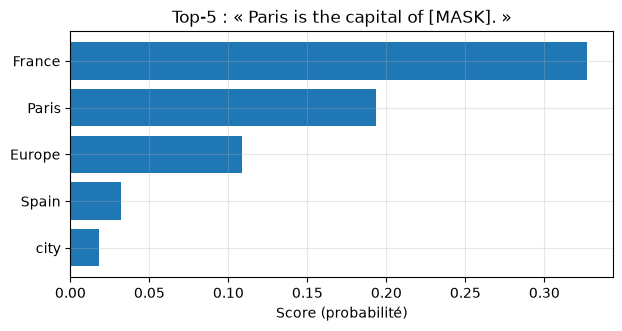

In [24]:
# Autres exemples : français, anglais et arabe
_ = show_fill_mask("Casablanca est la plus grande ville du [MASK].")
_ = show_fill_mask("Paris is the capital of [MASK].")

**Remarque : BERT est entraîné par Masked Language Modeling : on cache un mot et il doit prédire celui qui apparaît le plus souvent à cet endroit dans ses données. Il n’a aucune base de connaissances ni aucun objectif de vérité. Il apprend des statistiques de co-occurrence, et la bonne réponse factuelle peut perdre contre un mot simplement plus fréquent**

In [23]:
phrases = [
    "[MASK] est la capitale du Maroc.",
    "La capitale du Maroc est [MASK].",
    "Le Maroc a pour capitale [MASK].",
    "Rabat est la capitale du Maroc, et [MASK] est sa plus grande ville.",
]

for ph in phrases:
    txt = ph.replace("[MASK]", unmasker.tokenizer.mask_token)
    res = unmasker(txt, targets=["Rabat", "Casablanca"])
    print(ph)
    for r in res:
        print(f"   {r['token_str']:<12s} {r['score']:.4f}")

[MASK] est la capitale du Maroc.
   Casablanca   0.6750
   Rabat        0.0724
La capitale du Maroc est [MASK].
   Casablanca   0.6018
   Rabat        0.2365
Le Maroc a pour capitale [MASK].
   Rabat        0.3886
   Casablanca   0.3231
Rabat est la capitale du Maroc, et [MASK] est sa plus grande ville.
   Casablanca   0.4159
   Rabat        0.0414


# 2. Pourquoi "Casablanca" est premier au lieu de "Rabat" ?



- Bien que Rabat soit effectivement la capitale administrative du Maroc, le modèle statistique de BERT se base sur les probabilités d'apparition des mots dans ses données d'entraînement textuelles massives :

 **Casablanca est la plus grande métropole économique, le pôle financier et la ville la plus fréquemment mentionnée ou associée au Maroc dans de nombreux corpus textuels internationaux du web.**

 **Le score de Casablanca est donc plus élevé (0.6750), mais Rabat apparaît bien en 2ème position (0.0724), ce qui prouve que le modèle a parfaitement compris le contexte géographique de la phrase**

# 🏁 CONCLUSION – RNN vs LSTM vs Transformer vs GPT vs BERT

### Résultats de nos expériences

Sur la série `sin(x)`, les trois architectures séquentielles (RNN, LSTM, Transformer) atteignent une erreur très faible : la tâche est simple et la dépendance temporelle courte (10 pas). Retenez le **principe** plutôt que le classement exact — il dépend de la graine, des hyperparamètres et de la taille du jeu de données.

### Tableau comparatif

| Modèle | Principe | Avantages | Limites | Cas d'usage typiques |
|---|---|---|---|---|
| **RNN** | Récurrence : un état caché `h_t` mis à jour pas à pas | Simple, léger, peu de paramètres, bon pour séquences courtes | *Vanishing/exploding gradient*, mémoire courte, calcul **séquentiel** (lent, non parallélisable) | Petites séries temporelles, prototypes, systèmes embarqués |
| **LSTM** | RNN + cellule mémoire `c_t` + 3 portes | Mémoire à plus long terme, gradient plus stable | ~4× plus de paramètres qu'un RNN, toujours séquentiel, difficile à passer à l'échelle | Prévision de séries (finance, météo, capteurs), parole, texte de taille modeste |
| **Transformer** | Auto-attention multi-têtes + embeddings positionnels, **sans récurrence** | **Parallélisable**, dépendances longues directes (n'importe quelle paire de positions), très scalable | Coût **quadratique** `O(n²)` en longueur de séquence, gourmand en données/calcul, besoin d'encodage de position | Base de tous les LLM, traduction, vision (ViT), séries longues |
| **GPT** | Décodeur Transformer, **attention causale**, prédiction du prochain token | Génération fluide de texte, apprentissage few-shot / zero-shot, très polyvalent | Ne voit que le passé (contexte unidirectionnel), peut « halluciner », génération token par token, coûteux | Chatbots, génération de texte/code, résumé, assistants |
| **BERT** | Encodeur Transformer, **attention bidirectionnelle**, MLM | Excellente **compréhension** du contexte (gauche + droite), idéal pour l'*affinage* sur tâches précises | Pas conçu pour **générer** du texte, longueur de contexte limitée (512 tokens), taille de modèle importante | Classification, NER, question-réponse extractif, recherche sémantique, embeddings de phrases |

### Idées clés à retenir

1. **Du séquentiel au parallèle :** RNN → LSTM améliore la mémoire ; Transformer supprime la récurrence et gagne en parallélisme et en portée.
2. **Le masque fait la différence :** *avec* masque causal (triangulaire) → **GPT**, génératif ; *sans* masque (bidirectionnel) → **BERT**, compréhension.
3. **L'attention est coûteuse** (`O(n²)`) : c'est pourquoi des variantes efficaces (attention creuse, *FlashAttention*, etc.) existent pour les longs contextes.
4. **Pré-entraînement + affinage** (*transfer learning*) est le paradigme dominant : un modèle appris sur d'immenses corpus est ensuite adapté à votre tâche avec peu de données.
5. **Choisir selon le besoin :** petite série temporelle → LSTM/Transformer léger ; générer du texte → GPT ; comprendre/classifier du texte → BERT.

